## Message Intelligence System

**Import Libraries**

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from sklearn.naive_bayes import GaussianNB



**Load Dataset**

In [3]:
df = pd.read_csv("Message_Intelligence_Dataset_5200 - Message_Intelligence_Dataset_5200.csv")

print("Dataset Shape:", df.shape)
print("Dataset Columns:", df.columns.tolist())

print("Missing Values in each column:")
print(df.isnull().sum())

Dataset Shape: (5200, 16)
Dataset Columns: ['message_id', 'message_text', 'message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'timestamp', 'hour_of_day', 'day_of_week', 'spam_label']
Missing Values in each column:
message_id                   0
message_text                 0
message_length               0
word_count                   0
num_urls                     0
num_digits                   0
num_special_chars            0
spam_keyword_score           0
legit_keyword_score          0
sender_activity_score      106
sender_account_age_days    113
messages_sent_last_24h     162
timestamp                    0
hour_of_day                  0
day_of_week                  0
spam_label                   0
dtype: int64


**6. Identify input features and target variable**

In [4]:

X = df.drop(columns=["spam_label"])
y = df["spam_label"]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print("risk_status")

print("\nTarget Class Distribution:")
print(y.value_counts())


Input Features:
['message_id', 'message_text', 'message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'timestamp', 'hour_of_day', 'day_of_week']

Target Variable:
risk_status

Target Class Distribution:
spam_label
0    4227
1     973
Name: count, dtype: int64


**7. Perform basic data preprocessing**

In [5]:

# Check missing values
print("Missing values:")
print(X.isnull().sum())

# Create preprocessing pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("\nPreprocessing pipeline created.")
print("Missing values will be filled using median.")
print("Features will be scaled using StandardScaler.")


Missing values:
message_id                   0
message_text                 0
message_length               0
word_count                   0
num_urls                     0
num_digits                   0
num_special_chars            0
spam_keyword_score           0
legit_keyword_score          0
sender_activity_score      106
sender_account_age_days    113
messages_sent_last_24h     162
timestamp                    0
hour_of_day                  0
day_of_week                  0
dtype: int64

Preprocessing pipeline created.
Missing values will be filled using median.
Features will be scaled using StandardScaler.


**8. Split the dataset into training and testing sets**

In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training data: (4160, 15)
Testing data: (1040, 15)
Training samples: 4160
Testing samples: 1040


# Part C — K-Nearest Neighbors (KNN)

**9. Implement a KNN classifier**

In [7]:
numeric_cols = X.select_dtypes(include=["number"]).columns

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Keep only numerical columns for KNN
X = X[numeric_cols]

# Split dataset again
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Numerical features:", X.columns.tolist())
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Numerical features: ['message_id', 'message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']
Training shape: (4160, 13)
Testing shape: (1040, 13)


**10. Experiment with different values of K**

K = 3 Accuracy = 1.0
K = 5 Accuracy = 1.0
K = 7 Accuracy = 1.0
K = 9 Accuracy = 0.999
K = 11 Accuracy = 0.999


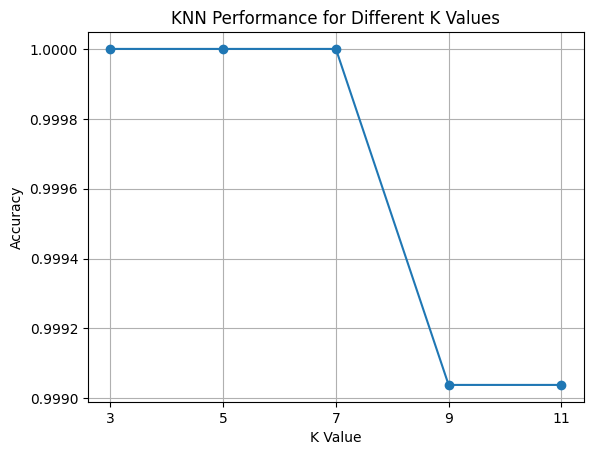

In [8]:

k_values = [3, 5, 7, 9, 11]
accuracies = []

for k in k_values:
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    accuracies.append(accuracy)

    print("K =", k, "Accuracy =", round(accuracy, 4))

plt.plot(k_values, accuracies, marker="o")
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN Performance for Different K Values")
plt.xticks(k_values)
plt.grid(True)
plt.show()


**11. Analyze how distance metrics affect predictions**

In [9]:

distance_metrics = ["euclidean", "manhattan", "minkowski"]

for metric in distance_metrics:
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            metric=metric
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("\nDistance Metric:", metric)
    print("Accuracy:",
          accuracy_score(y_test, predictions))
    print("F1 Score:",
          f1_score(y_test, predictions, zero_division=0))



Distance Metric: euclidean
Accuracy: 1.0
F1 Score: 1.0

Distance Metric: manhattan
Accuracy: 1.0
F1 Score: 1.0

Distance Metric: minkowski
Accuracy: 1.0
F1 Score: 1.0


**12. Identify cases where KNN misclassifies messages**

In [10]:


knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

y_pred_knn = pd.Series(y_pred_knn, index=X_test.index)

misclassified = X_test[
    y_test != y_pred_knn
].copy()

misclassified["Actual"] = y_test.loc[misclassified.index]
misclassified["Predicted"] = y_pred_knn.loc[misclassified.index]

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Total Misclassified Messages:", len(misclassified))

print("\nFirst 10 Misclassified Messages:")
print(misclassified.head(10))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))


KNN Accuracy: 1.0
Total Misclassified Messages: 0

First 10 Misclassified Messages:
Empty DataFrame
Columns: [message_id, message_length, word_count, num_urls, num_digits, num_special_chars, spam_keyword_score, legit_keyword_score, sender_activity_score, sender_account_age_days, messages_sent_last_24h, hour_of_day, day_of_week, Actual, Predicted]
Index: []

Confusion Matrix:
[[845   0]
 [  0 195]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       845
           1       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



# Part D — Support Vector Machine (SVM)

**13. Implement SVM with Linear, RBF and Polynomial kernels**

In [11]:

kernels = ["linear", "rbf", "poly"]
svm_models = {}

for kernel in kernels:
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", SVC(
            kernel=kernel,
            class_weight="balanced"
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    svm_models[kernel] = model

    print("\nKernel:", kernel)
    print("Accuracy:",
          accuracy_score(y_test, predictions))
    print("Precision:",
          precision_score(
              y_test, predictions, zero_division=0
          ))
    print("Recall:",
          recall_score(
              y_test, predictions, zero_division=0
          ))
    print("F1 Score:",
          f1_score(
              y_test, predictions, zero_division=0
          ))



Kernel: linear
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Kernel: rbf
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Kernel: poly
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


**14. Analyze margin separation and support vectors**

In [12]:

svm_model = svm_models["linear"]

svm_classifier = svm_model.named_steps["classifier"]

print("Support vectors per class:")
print(svm_classifier.n_support_)

print("\nTotal Support Vectors:")
print(svm_classifier.n_support_.sum())

print("\nSupport vectors as a percentage of training data:")
print(round(
    svm_classifier.n_support_.sum()
    / len(X_train) * 100, 2
), "%")

print("\nLinear SVM Coefficients:")
print(svm_classifier.coef_)


Support vectors per class:
[8 4]

Total Support Vectors:
12

Support vectors as a percentage of training data:
0.29 %

Linear SVM Coefficients:
[[ 0.00559752 -0.13965759  0.05326552  0.14878888 -0.0379561   1.02001443
   0.08786919 -0.12107716 -0.02124964 -0.0326975   0.07085096 -0.00872417
   0.0187984 ]]


**15. Compare SVM performance with KNN**

       Model  Accuracy  Precision  Recall  F1 Score
   KNN (K=5)       1.0        1.0     1.0       1.0
SVM (linear)       1.0        1.0     1.0       1.0
   SVM (rbf)       1.0        1.0     1.0       1.0
  SVM (poly)       1.0        1.0     1.0       1.0


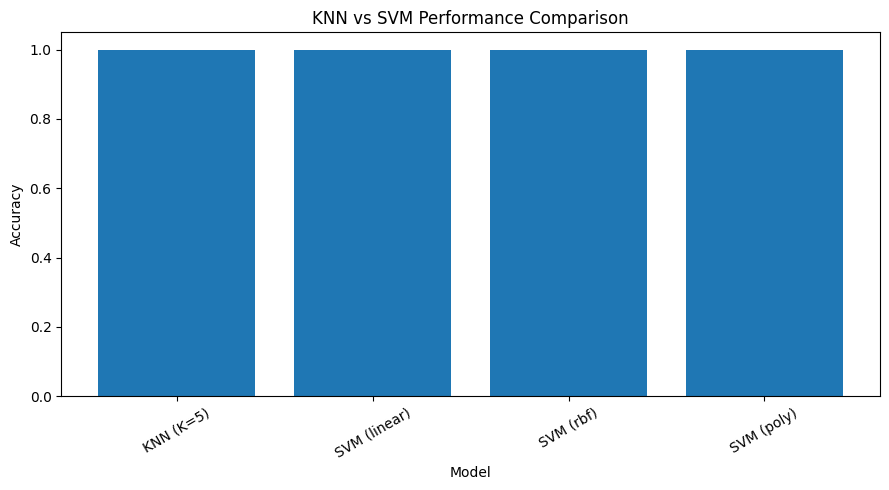

In [13]:

comparison = []

# KNN evaluation
knn_predictions = knn_model.predict(X_test)

comparison.append({
    "Model": "KNN (K=5)",
    "Accuracy": accuracy_score(y_test, knn_predictions),
    "Precision": precision_score(
        y_test, knn_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, knn_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, knn_predictions, zero_division=0
    )
})

# SVM evaluation
for kernel, model in svm_models.items():
    predictions = model.predict(X_test)

    comparison.append({
        "Model": "SVM (" + kernel + ")",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(3).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.bar(comparison_df["Model"], comparison_df["Accuracy"])
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("KNN vs SVM Performance Comparison")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Part E: Naive Bayes Classifier & Probability

**16. Implement Naive Bayes Classifier**

In [14]:
nb_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", GaussianNB())
])

# Train the model
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test)

# Evaluate model
print("Naive Bayes Accuracy:",
      accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_nb, zero_division=0
))

Naive Bayes Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       845
           1       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



**18. Demonstrate Bayes' Theorem**

In [15]:

# Example probabilities
p_spam = 0.40
p_url_given_spam = 0.75
p_url_given_not_spam = 0.20

p_not_spam = 1 - p_spam

# Total probability of a URL
p_url = (
    p_url_given_spam * p_spam
    + p_url_given_not_spam * p_not_spam
)

# Bayes' theorem
p_spam_given_url = (
    p_url_given_spam * p_spam / p_url
)

print("Probability of Spam:", p_spam)
print("Probability of URL:", p_url)
print("Probability of Spam given URL:", p_spam_given_url)


Probability of Spam: 0.4
Probability of URL: 0.42000000000000004
Probability of Spam given URL: 0.7142857142857143


**19. Compare theoretical probabilities with model predictions**

In [16]:

# Compare actual labels and Naive Bayes predictions
comparison = pd.DataFrame({
    "Actual": y_test,
    "Naive_Bayes_Predicted": y_pred_nb
})

print(comparison.head(10))

print("\nPrediction Agreement:")
print(
    (comparison["Actual"] ==
     comparison["Naive_Bayes_Predicted"]).mean()
)


      Actual  Naive_Bayes_Predicted
799        0                      0
655        1                      1
5075       0                      0
4087       0                      0
877        0                      0
3088       0                      0
4516       0                      0
1319       0                      0
3852       0                      0
4997       0                      0

Prediction Agreement:
1.0


# Part F: Model Comparison & Evaluation

Model Comparison:
         Model  Accuracy  Precision  Recall  F1 Score
0          KNN       1.0        1.0     1.0       1.0
1          SVM       1.0        1.0     1.0       1.0
2  Naive Bayes       1.0        1.0     1.0       1.0


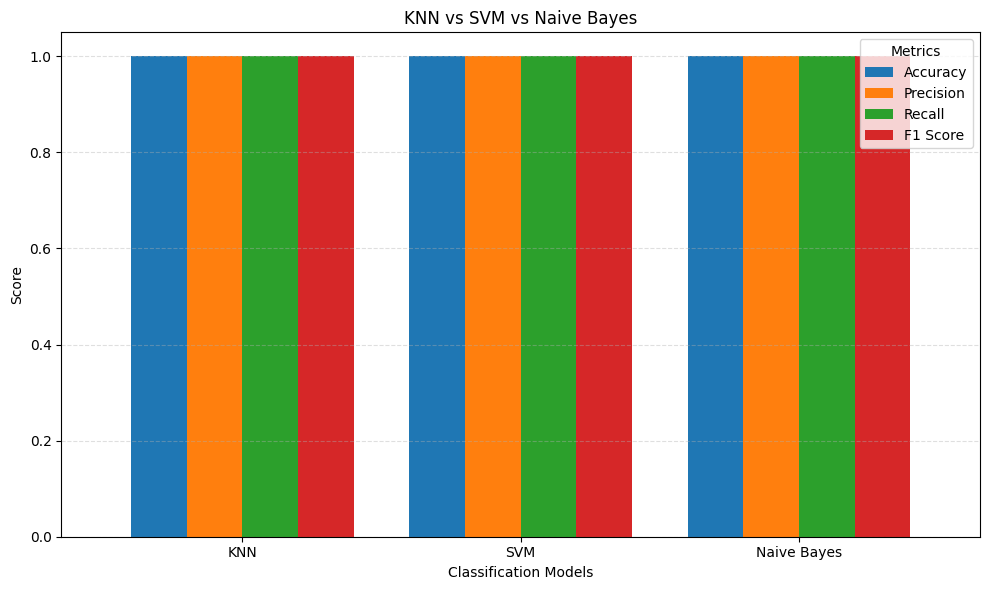

In [18]:
y_pred_knn = knn_model.predict(X_test)
y_pred_svm = svm_model.predict(X_test)
y_pred_nb = nb_model.predict(X_test)

# Compare models
models = {
    "KNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Naive Bayes": y_pred_nb
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="binary",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="binary",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="binary",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Model Comparison:")
print(results_df.round(4))

# Create comparison graph
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

ax = results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("KNN vs SVM vs Naive Bayes")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**22. Identify the best model**

In [19]:

best_precision_model = results_df.loc[
    results_df["Precision"].idxmax()
]

best_recall_model = results_df.loc[
    results_df["Recall"].idxmax()
]

print("Best Model for High Precision:")
print(best_precision_model)

print("\nBest Model for High Recall:")
print(best_recall_model)


Best Model for High Precision:
Model        KNN
Accuracy     1.0
Precision    1.0
Recall       1.0
F1 Score     1.0
Name: 0, dtype: object

Best Model for High Recall:
Model        KNN
Accuracy     1.0
Precision    1.0
Recall       1.0
F1 Score     1.0
Name: 0, dtype: object


# Conclusion



In this project, we implemented and evaluated three machine learning classification algorithms: K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and Naive Bayes to classify messages. The dataset was analyzed and preprocessed before training the models.

We evaluated the models using important performance metrics, including Accuracy, Precision, Recall, and F1 Score. We also examined misclassified messages, generated confusion matrices, calculated conditional probabilities, and applied Bayes’ Theorem to understand probabilistic classification.

The performance comparison helped us understand the strengths and limitations of each algorithm. Precision is useful for reducing false spam predictions, while recall helps identify a greater proportion of actual spam messages. The most suitable model can be selected based on the project’s requirements and the evaluation results.

Overall, this project provided practical experience in data preprocessing, supervised machine learning, probability, model evaluation, and visualization. It demonstrates how machine learning techniques can be applied to message classification and can be further improved with feature engineering, hyperparameter tuning, and additional testing.